In [6]:
import pandas as pd 
import numpy as np
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/dataset-diabete-6ab953aea55fc643490108.csv")

df.columns




Index(['   ', ' Pregnancies', ' Glucose', ' BloodPressure', ' SkinThickness',
       ' Insulin', ' BMI ', ' DiabetesPedigreeFunction', ' Age'],
      dtype='str')

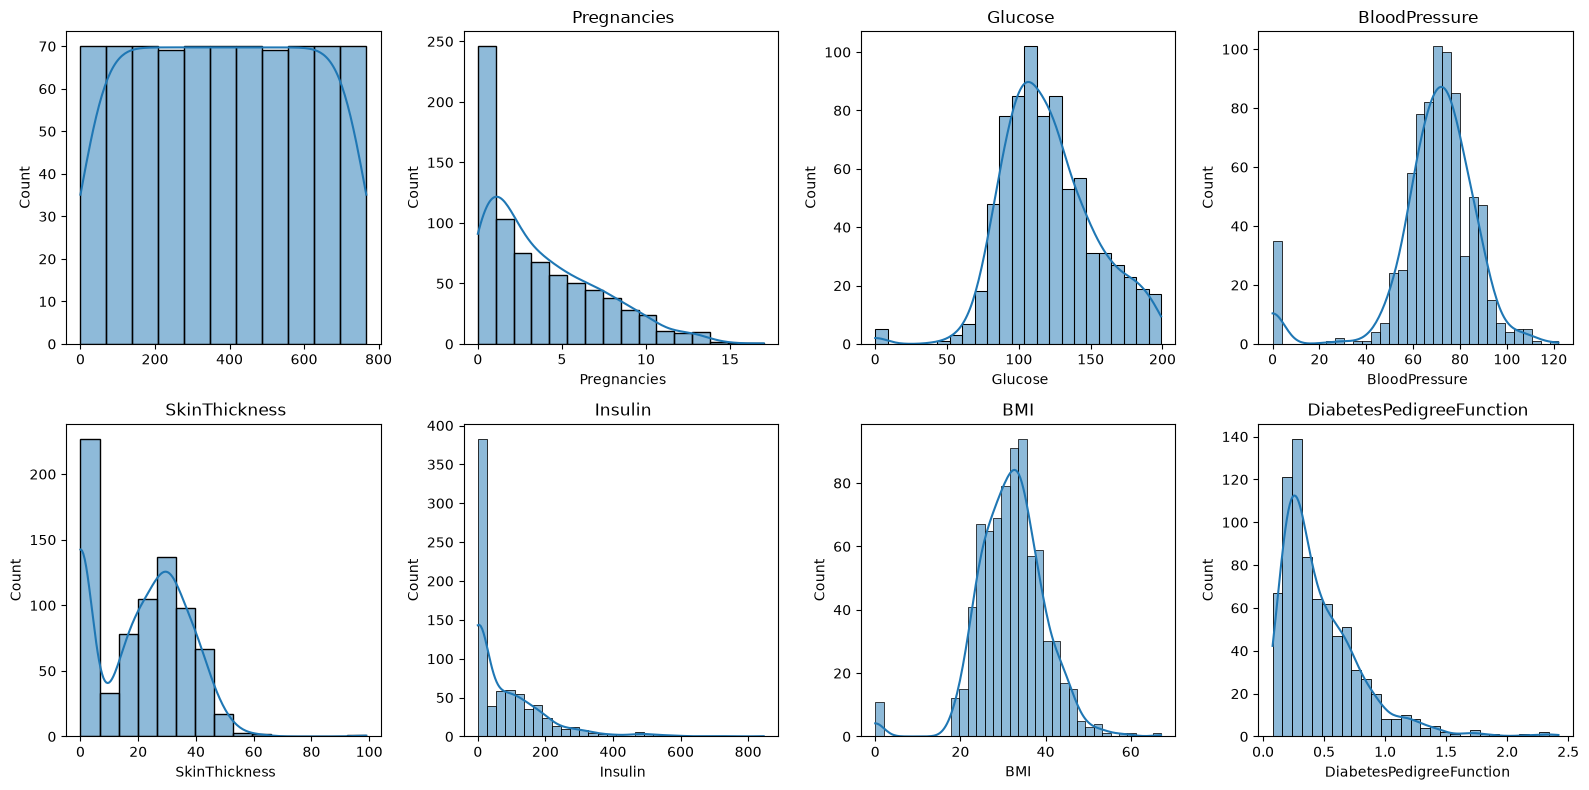

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()

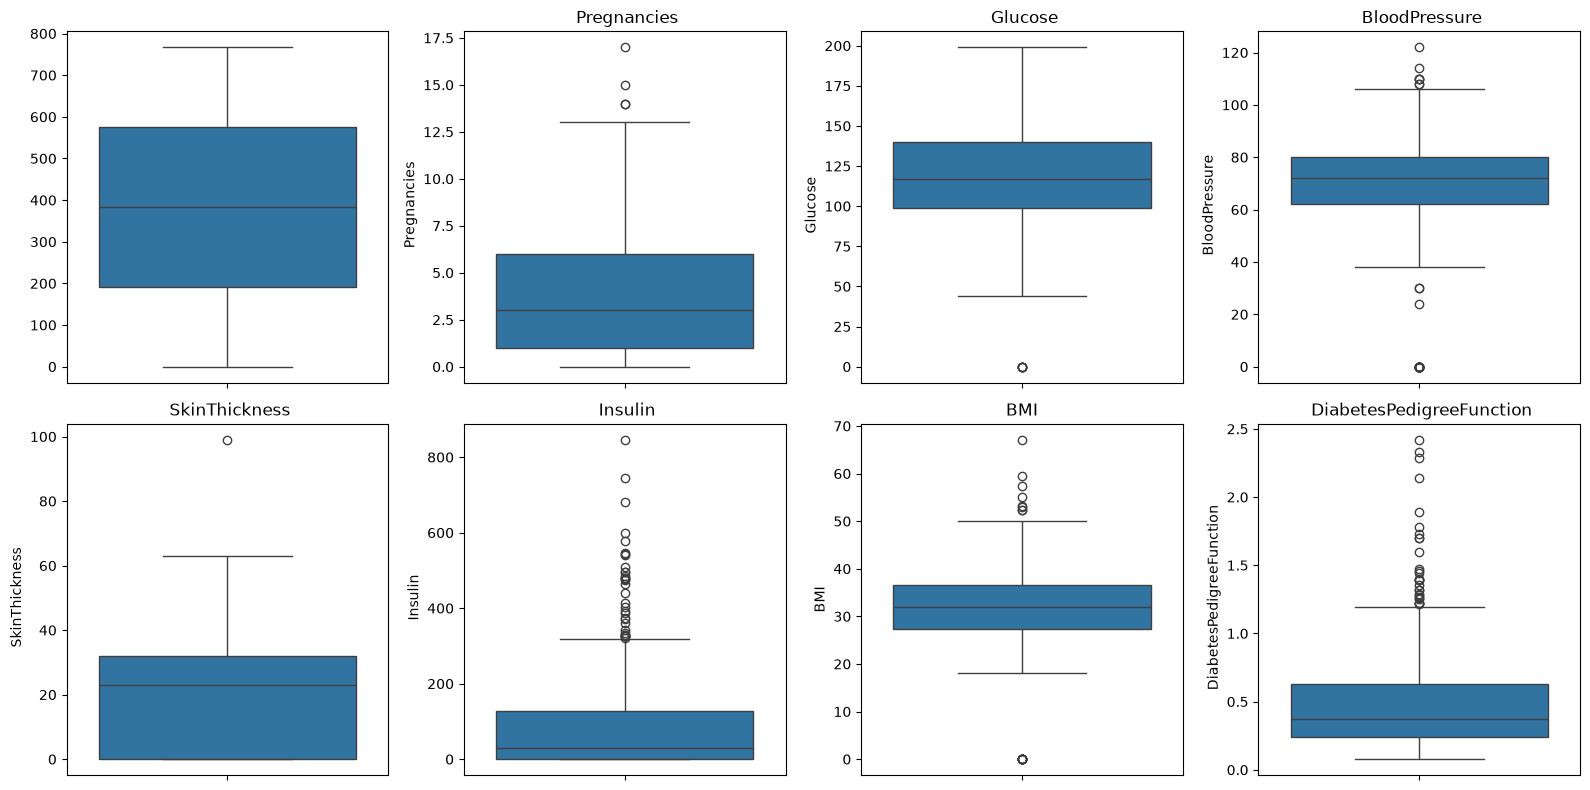

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, df.columns):
    sns.boxplot(df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()

In [5]:
# Configuration de l'affichage matplotlib / seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Chargement du dataset (remplacez par le nom exact de votre fichier)
df = pd.read_csv('../data/raw/dataset-diabete-6ab953aea55fc643490108.csv')

# 2. Nettoyage des noms de colonnes (suppression des espaces superflus)
df.columns = df.columns.str.strip()

# 3. Suppression de la première colonne d'index inutile si elle existe (colonne vide)
if '' in df.columns or 'Unnamed: 0' in df.columns:
    df = df.drop(columns=[col for col in df.columns if 'Unnamed' in col or col == ''])

# Aperçu des 5 premières lignes et des dimensions
print(f"Dimensions du jeu de données : {df.shape[0]} lignes, {df.shape[1]} colonnes\n")
df.head()

Dimensions du jeu de données : 768 lignes, 8 colonnes



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [ ]:
li=[1,2,3,6,7,80]


(768, 9)

In [9]:
df.describe()

,,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,383.500000,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,221.846794,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,191.750000,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,383.500000,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,575.250000,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,767.000000,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


In [6]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')

In [7]:
# Colonnes où la valeur 0 est physiquement impossible pour un patient vivant
clinical_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Remplacement des 0 par NaN pour faire apparaître les vraies valeurs manquantes
df_clean = df.copy()
df_clean[clinical_zero_cols] = df_clean[clinical_zero_cols].replace(0, np.nan)

# Affichage du bilan des valeurs manquantes
missing_summary = pd.DataFrame({
    'Zeros_Initial': (df[clinical_zero_cols] == 0).sum(),
    'Manquants_NaN': df_clean[clinical_zero_cols].isnull().sum(),
    'Pourcentage_%': (df_clean[clinical_zero_cols].isnull().sum() / len(df_clean)) * 100
})

missing_summary


,Zeros_Initial,Manquants_NaN,Pourcentage_%
Glucose,5,5,0.651042
BloodPressure,35,35,4.557292
SkinThickness,227,227,29.557292
Insulin,374,374,48.697917
BMI,11,11,1.432292


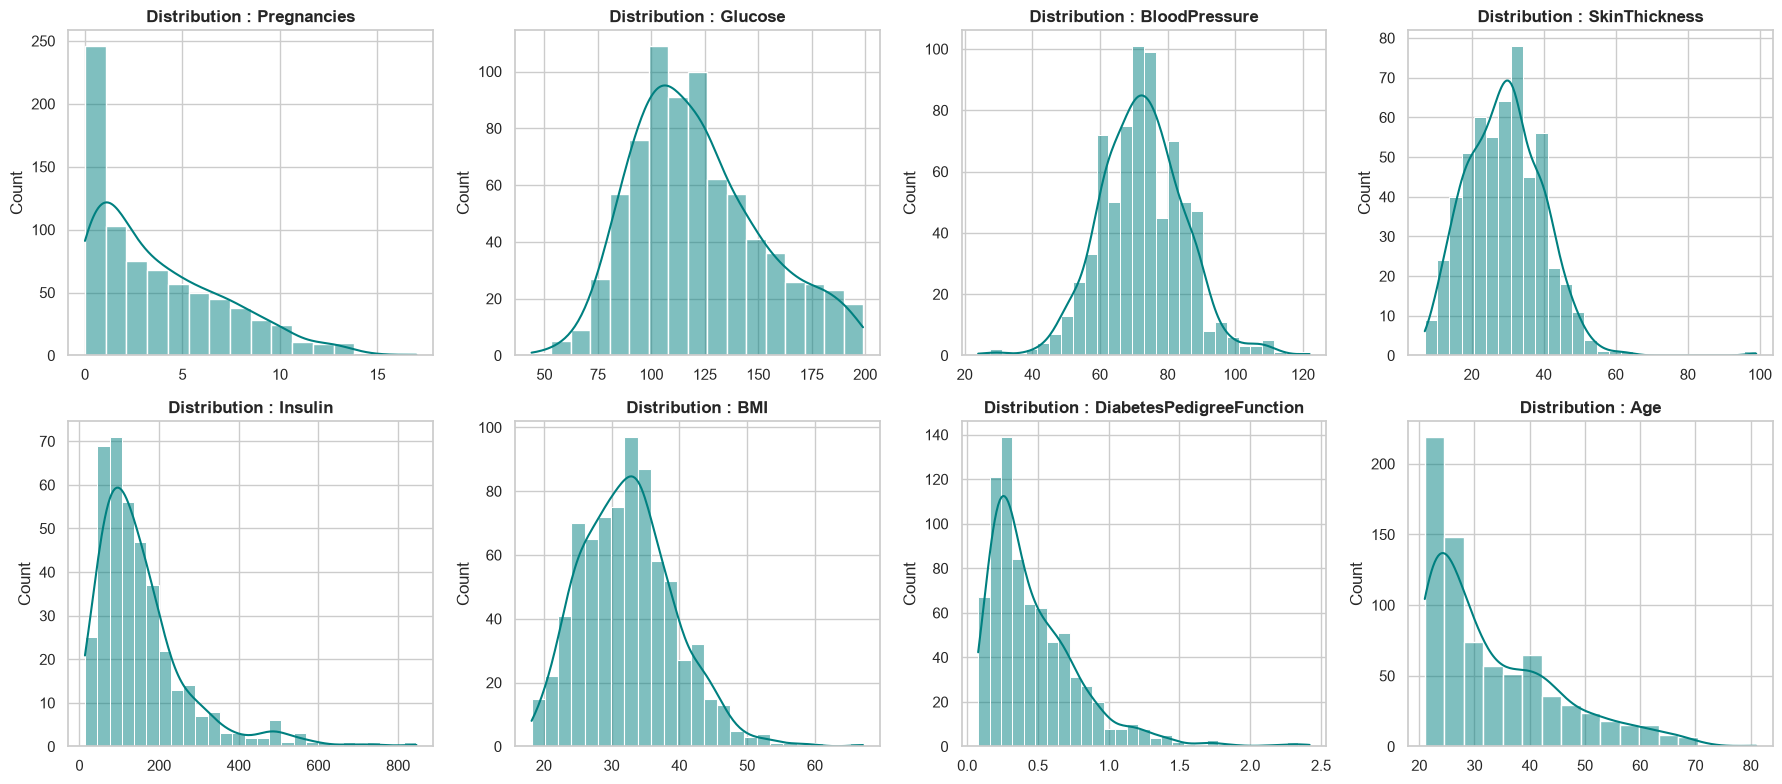

In [8]:
# Grille de distribution des variables cliniques
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

features = [col for col in df_clean.columns if col != 'Pregnancies']

for i, col in enumerate(df_clean.columns):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution : {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

In [9]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Traitement des faux zéro (remplacement par NaN)
clinical_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean = df.copy()
df_clean[clinical_zero_cols] = df_clean[clinical_zero_cols].replace(0, np.nan)

# 2. Imputation par la Médiane (Évite le blocage DLL de _kd_tree)
df_imputed = df_clean.copy()
for col in clinical_zero_cols:
    median_val = df_imputed[col].median()
    df_imputed[col] = df_imputed[col].fillna(median_val)

# 3. Traitement des outliers par Capping (quantiles 1% - 99%)
df_capped = df_imputed.copy()
for col in df_capped.columns:
    lower_limit = df_capped[col].quantile(0.01)
    upper_limit = df_capped[col].quantile(0.99)
    df_capped[col] = np.clip(df_capped[col], lower_limit, upper_limit)

# 4. Standardisation des variables (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_capped)
df_scaled = pd.DataFrame(X_scaled, columns=df_capped.columns)

# 5. Exportation des fichiers dans data/processed/
os.makedirs('../data/processed', exist_ok=True)

df_capped.to_csv('../data/processed/df_capped.csv', index=False)
df_scaled.to_csv('../data/processed/df_scaled.csv', index=False)

print("✅ Fichiers sauvegardés avec succès dans 'data/processed/':")
print("  - df_capped.csv")
print("  - df_scaled.csv")

✅ Fichiers sauvegardés avec succès dans 'data/processed/':
  - df_capped.csv
  - df_scaled.csv
